# Diabetic Retinopathy: Simple Dataset EDA


In [1]:
from pathlib import Path
import sys
import io
import os

PROJECT_ROOT = Path(r"D:\M L\Diabetic_Retinopathy_Detection_mini_project")
sys.path.insert(0, str(PROJECT_ROOT))
if (PROJECT_ROOT / "project_paths.py").exists():
    from project_paths import PROJECT_ROOT
PROJECT_ROOT = Path(PROJECT_ROOT)

CONFIGS = ("1M", "250K", "btgraham-300")
CONFIG = "250K"  # Format used for EDA only
DATASET_DIR = PROJECT_ROOT / "data" / CONFIG  # contains dataset_info.json
SAMPLE_DIR = PROJECT_ROOT / "data" / "demo_samples"

IMAGE_SAMPLE_SIZE = 300
SAMPLES_PER_CLASS = 3
PREVIEW_SIZE = 384
SEED = 42

os.environ["TFDS_DISABLE_GCS"] = "1"
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
LABELS = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]
GRADE_NAMES = [f"{i}: {name}" for i, name in enumerate(LABELS)]
COLORS = ["#2878B5", "#31A354", "#E6AB02", "#E76F51", "#9A4885"]
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__, "| TFDS:", tfds.__version__)
print("Reading:", DATASET_DIR)

Kernel: C:\Users\kawal\miniconda3\envs\dr_tf\python.exe
TensorFlow: 2.10.1 | TFDS: 4.8.3
Reading: D:\M L\Diabetic_Retinopathy_Detection_mini_project\data\250K


## Dataset overview


,Images
sample,10
train,35126
validation,10906
test,42670


Features: FeaturesDict({
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=5),
    'name': Text(shape=(), dtype=string),
})
Dataset version: 3.0.0


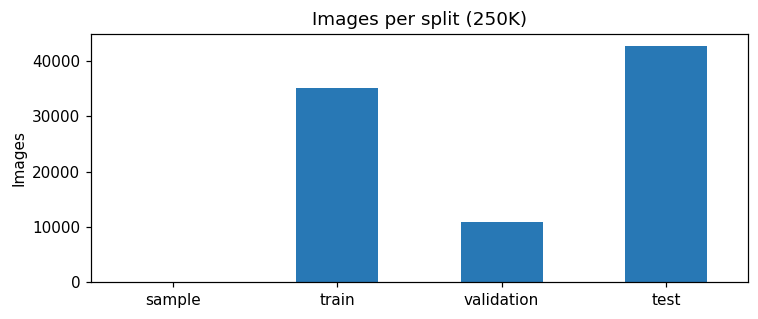

In [2]:
assert (DATASET_DIR / "dataset_info.json").exists(), f"Check DATASET_DIR: {DATASET_DIR}"
builder = tfds.builder_from_directory(str(DATASET_DIR))
assert builder.info.name == "diabetic_retinopathy_detection"
split_sizes = pd.Series(
    {name: split.num_examples for name, split in builder.info.splits.items()},
    name="Images",
)
display(split_sizes.to_frame())
print("Features:", builder.info.features)
print("Dataset version:", builder.info.version)

split_sizes.plot.bar(color="#2878B5", figsize=(7, 3), rot=0)
plt.title(f"Images per split ({CONFIG})")
plt.ylabel("Images")
plt.tight_layout()
plt.show()

SPLITS = [s for s in ("train", "validation", "test") if s in split_sizes.index]
assert "train" in SPLITS and split_sizes["train"] > 0

In [3]:
rng = np.random.default_rng(SEED)
sample_indices = set(rng.choice(
    int(split_sizes["train"]),
    size=min(IMAGE_SAMPLE_SIZE, int(split_sizes["train"])),
    replace=False,
).tolist())

rows, image_rows = [], []
examples = {grade: [] for grade in range(5)}
read_config = tfds.ReadConfig(try_autocache=False)

for split in SPLITS:
    ds = builder.as_dataset(
        split=split, shuffle_files=False,
        decoders={"image": tfds.decode.SkipDecoding()},
        read_config=read_config,
    )
    # Other splits need only names and labels, not image bytes in Python.
    if split != "train":
        ds = ds.map(lambda x: {"name": x["name"], "label": x["label"]})
    for index, item in enumerate(tqdm(tfds.as_numpy(ds), total=int(split_sizes[split]), desc=split)):
        name = item["name"].decode("utf-8")
        grade = int(item["label"])
        rows.append((split, name, grade))
        keep_demo = split == "train" and grade in examples and len(examples[grade]) < SAMPLES_PER_CLASS
        keep_stats = split == "train" and index in sample_indices
        if keep_demo or keep_stats:
            with Image.open(io.BytesIO(item["image"])) as source:
                image = source.convert("RGB")
            width, height = image.size
            image.thumbnail((PREVIEW_SIZE, PREVIEW_SIZE), Image.Resampling.LANCZOS)
            if keep_stats:
                gray = np.asarray(image.convert("L"), dtype=np.float32)
                image_rows.append({
                    "name": name, "label": grade, "width": width, "height": height,
                    "aspect_ratio": width / height,
                    "brightness": float(gray.mean()), "contrast": float(gray.std()),
                })
            if keep_demo:
                examples[grade].append((name, image))

metadata = pd.DataFrame(rows, columns=["split", "name", "label"])
image_stats = pd.DataFrame(image_rows)
del rows
display(metadata.head())
print(f"Labels read: {len(metadata):,}; training images measured: {len(image_stats):,}")

train:   0%|          | 0/35126 [00:00<?, ?it/s]

validation:   0%|          | 0/10906 [00:00<?, ?it/s]

test:   0%|          | 0/42670 [00:00<?, ?it/s]

,split,name,label
0,train,13816_right,0
1,train,7654_left,0
2,train,37320_right,1
3,train,21820_right,0
4,train,41451_left,3


Labels read: 88,702; training images measured: 300


## Basic integrity checks

Check actual counts against metadata, invalid labels, empty names and repeated image IDs. 

In [4]:
checks = metadata.groupby("split").agg(
    actual_images=("name", "size"),
    unique_names=("name", "nunique"),
    invalid_labels=("label", lambda x: (~x.isin(range(5))).sum()),
    empty_names=("name", lambda x: x.str.strip().eq("").sum()),
).reindex(SPLITS)
checks["expected_images"] = split_sizes.reindex(SPLITS)
checks["count_matches"] = checks["actual_images"] == checks["expected_images"]
checks["duplicate_names"] = checks["actual_images"] - checks["unique_names"]
display(checks)
print("Repeated names across all main splits:",
      int(metadata["name"].duplicated().sum()))
valid = metadata[metadata["label"].isin(range(5))].copy()
print("Class plots below exclude invalid labels, if any. Investigate any failed checks.")

,actual_images,unique_names,invalid_labels,empty_names,expected_images,count_matches,duplicate_names
split,,,,,,,
train,35126,35126,0,0,35126,True,0
validation,10906,10906,0,0,10906,True,0
test,42670,42670,0,0,42670,True,0


Repeated names across all main splits: 0
Class plots below exclude invalid labels, if any. Investigate any failed checks.


## Label distribution and imbalance


Grade,0: No DR,1: Mild,2: Moderate,3: Severe,4: Proliferative DR
split,,,,,
train,25810,2443,5292,873,708
validation,8130,720,1579,237,240
test,31403,3042,6282,977,966


label,0: No DR,1: Mild,2: Moderate,3: Severe,4: Proliferative DR
split,,,,,
train,73.48,6.95,15.07,2.49,2.02
validation,74.55,6.60,14.48,2.17,2.20
test,73.60,7.13,14.72,2.29,2.26


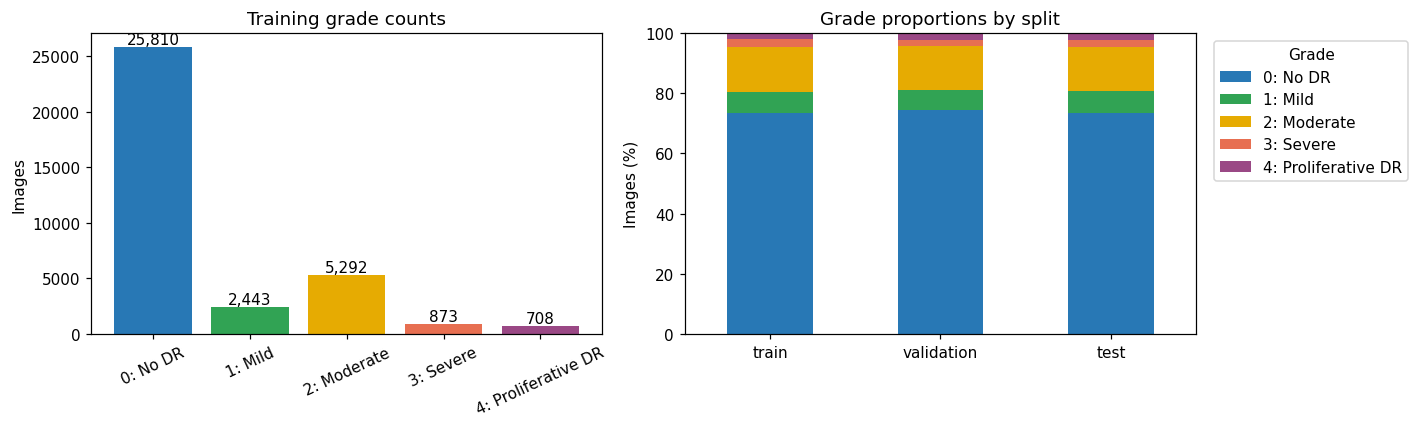

,Training summary
Valid training images,35126.00
Missing training grades,0.00
Majority-class baseline accuracy (%),73.48
Largest / smallest present class,36.45


In [5]:
counts = pd.crosstab(valid["split"], valid["label"]).reindex(
    index=SPLITS, columns=range(5), fill_value=0
)
percentages = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
display(counts.rename(columns=dict(enumerate(GRADE_NAMES))).rename_axis(columns="Grade"))
display(percentages.rename(columns=dict(enumerate(GRADE_NAMES))).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train_counts = counts.loc["train"]
axes[0].bar(GRADE_NAMES, train_counts, color=COLORS)
for i, n in enumerate(train_counts):
    axes[0].text(i, n, f"{n:,}", ha="center", va="bottom")
axes[0].set(title="Training grade counts", ylabel="Images")
axes[0].tick_params(axis="x", rotation=25)
percentages.rename(columns=dict(enumerate(GRADE_NAMES))).plot.bar(
    stacked=True, color=COLORS, ax=axes[1], rot=0
)
axes[1].set(title="Grade proportions by split", ylabel="Images (%)", xlabel="", ylim=(0, 100))
axes[1].legend(title="Grade", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

assert train_counts.sum() > 0, "No valid training labels."
positive_counts = train_counts[train_counts > 0]
display(pd.Series({
    "Valid training images": int(train_counts.sum()),
    "Missing training grades": int((train_counts == 0).sum()),
    "Majority-class baseline accuracy (%)": round(100 * train_counts.max() / train_counts.sum(), 2),
    "Largest / smallest present class": round(positive_counts.max() / positive_counts.min(), 2),
}, name="Training summary").to_frame())

## Patient overlap and left/right eyes

Names such as `123_left` and `123_right` refer to the same patient. Check patient IDs as well as image IDs before accepting a train/validation/test split. The matrix diagonal is the number of unique IDs; off-diagonal entries are shared IDs. Missing or unexpected names are counted separately.

Names not matching patient_eye: 0


,train,validation,test
Shared image IDs,,,
train,35126,0,0
validation,0,10906,0
test,0,0,42670


,train,validation,test
Shared patient IDs,,,
train,17563,0,0
validation,0,5453,0
test,0,0,21335


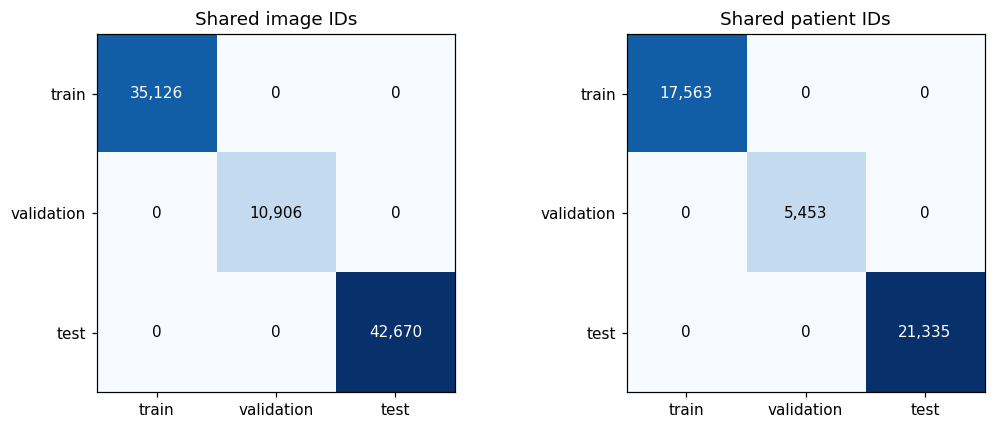

eye,left,right
split,,
train,17563,17563
validation,5453,5453
test,21335,21335


Any off-diagonal overlap needs review. Keep both eyes of a patient in one split.


In [6]:
parts = metadata["name"].str.replace(r"\.[^.]+$", "", regex=True).str.extract(
    r"^(?P<patient>\d+)_(?P<eye>left|right)$"
)
metadata[["patient", "eye"]] = parts
print("Names not matching patient_eye:", int(metadata["patient"].isna().sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column, title in zip(axes, ["name", "patient"], ["Shared image IDs", "Shared patient IDs"]):
    sets = {s: set(metadata.loc[metadata["split"] == s, column].dropna()) for s in SPLITS}
    overlap = pd.DataFrame(
        [[len(sets[a] & sets[b]) for b in SPLITS] for a in SPLITS],
        index=SPLITS, columns=SPLITS,
    )
    display(overlap.rename_axis(title))
    ax.imshow(overlap.values, cmap="Blues")
    ax.set_xticks(range(len(SPLITS)), SPLITS)
    ax.set_yticks(range(len(SPLITS)), SPLITS)
    ax.set_title(title)
    for i in range(len(SPLITS)):
        for j in range(len(SPLITS)):
            value = overlap.iloc[i, j]
            ax.text(j, i, f"{value:,}", ha="center", va="center",
                    color="white" if value > overlap.values.max() / 2 else "black")
plt.tight_layout()
plt.show()

eye_counts = pd.crosstab(metadata["split"], metadata["eye"]).reindex(
    index=SPLITS, columns=["left", "right"], fill_value=0
)
display(eye_counts)
print("Any off-diagonal overlap needs review. Keep both eyes of a patient in one split.")

## Image dimensions and basic appearance


,width,height,aspect_ratio,brightness,contrast
count,300.00,300.00,300.00,300.00,300.00
mean,603.17,413.59,1.46,62.37,51.67
std,19.43,12.47,0.07,26.74,16.26
min,400.00,315.00,1.12,6.92,8.39
25%,612.00,408.00,1.50,45.28,39.41
50%,612.00,408.00,1.50,57.35,52.57
75%,612.00,408.25,1.50,75.18,63.50
max,615.00,472.00,1.51,145.26,99.23


,Images in random sample
0: No DR,223
1: Mild,24
2: Moderate,39
3: Severe,9
4: Proliferative DR,5


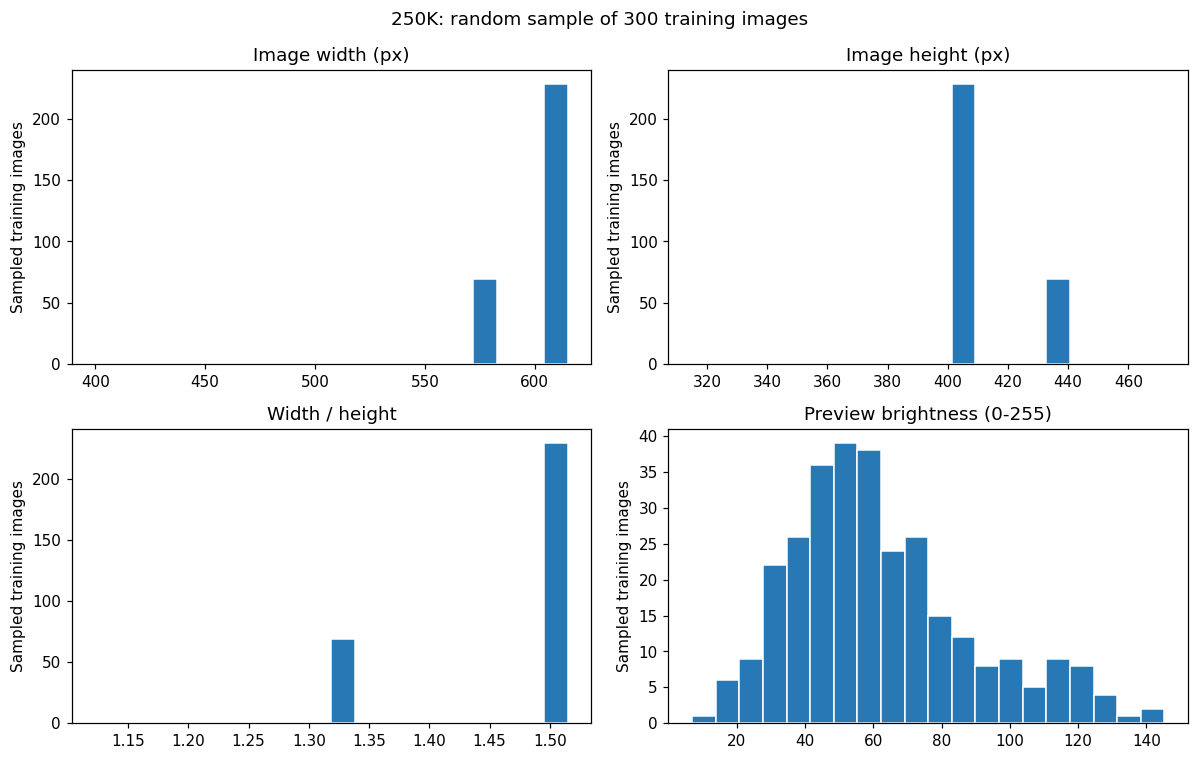

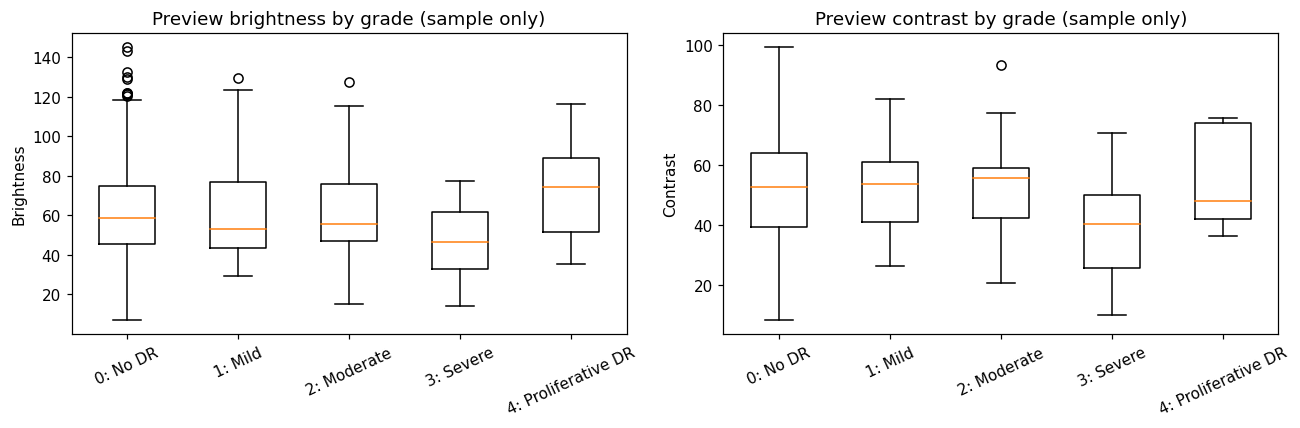

In [7]:
display(image_stats[["width", "height", "aspect_ratio", "brightness", "contrast"]].describe().round(2))
display(image_stats["label"].value_counts().reindex(range(5), fill_value=0)
        .rename(index=dict(enumerate(GRADE_NAMES))).to_frame("Images in random sample"))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column, title in zip(
    axes.flat, ["width", "height", "aspect_ratio", "brightness"],
    ["Image width (px)", "Image height (px)", "Width / height", "Preview brightness (0-255)"]
):
    ax.hist(image_stats[column], bins=20, color="#2878B5", edgecolor="white")
    ax.set(title=title, ylabel="Sampled training images")
fig.suptitle(f"{CONFIG}: random sample of {len(image_stats)} training images")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
present_grades = sorted(image_stats.loc[image_stats["label"].isin(range(5)), "label"].unique())
for ax, metric in zip(axes, ["brightness", "contrast"]):
    ax.boxplot(
        [image_stats.loc[image_stats["label"] == grade, metric] for grade in present_grades],
        labels=[GRADE_NAMES[grade] for grade in present_grades],
    )
    ax.set(title=f"Preview {metric} by grade (sample only)", ylabel=metric.capitalize())
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## Show the dataset: examples from each grade

Training images with the **dataset-provided labels**. Each preview keeps its aspect ratio.

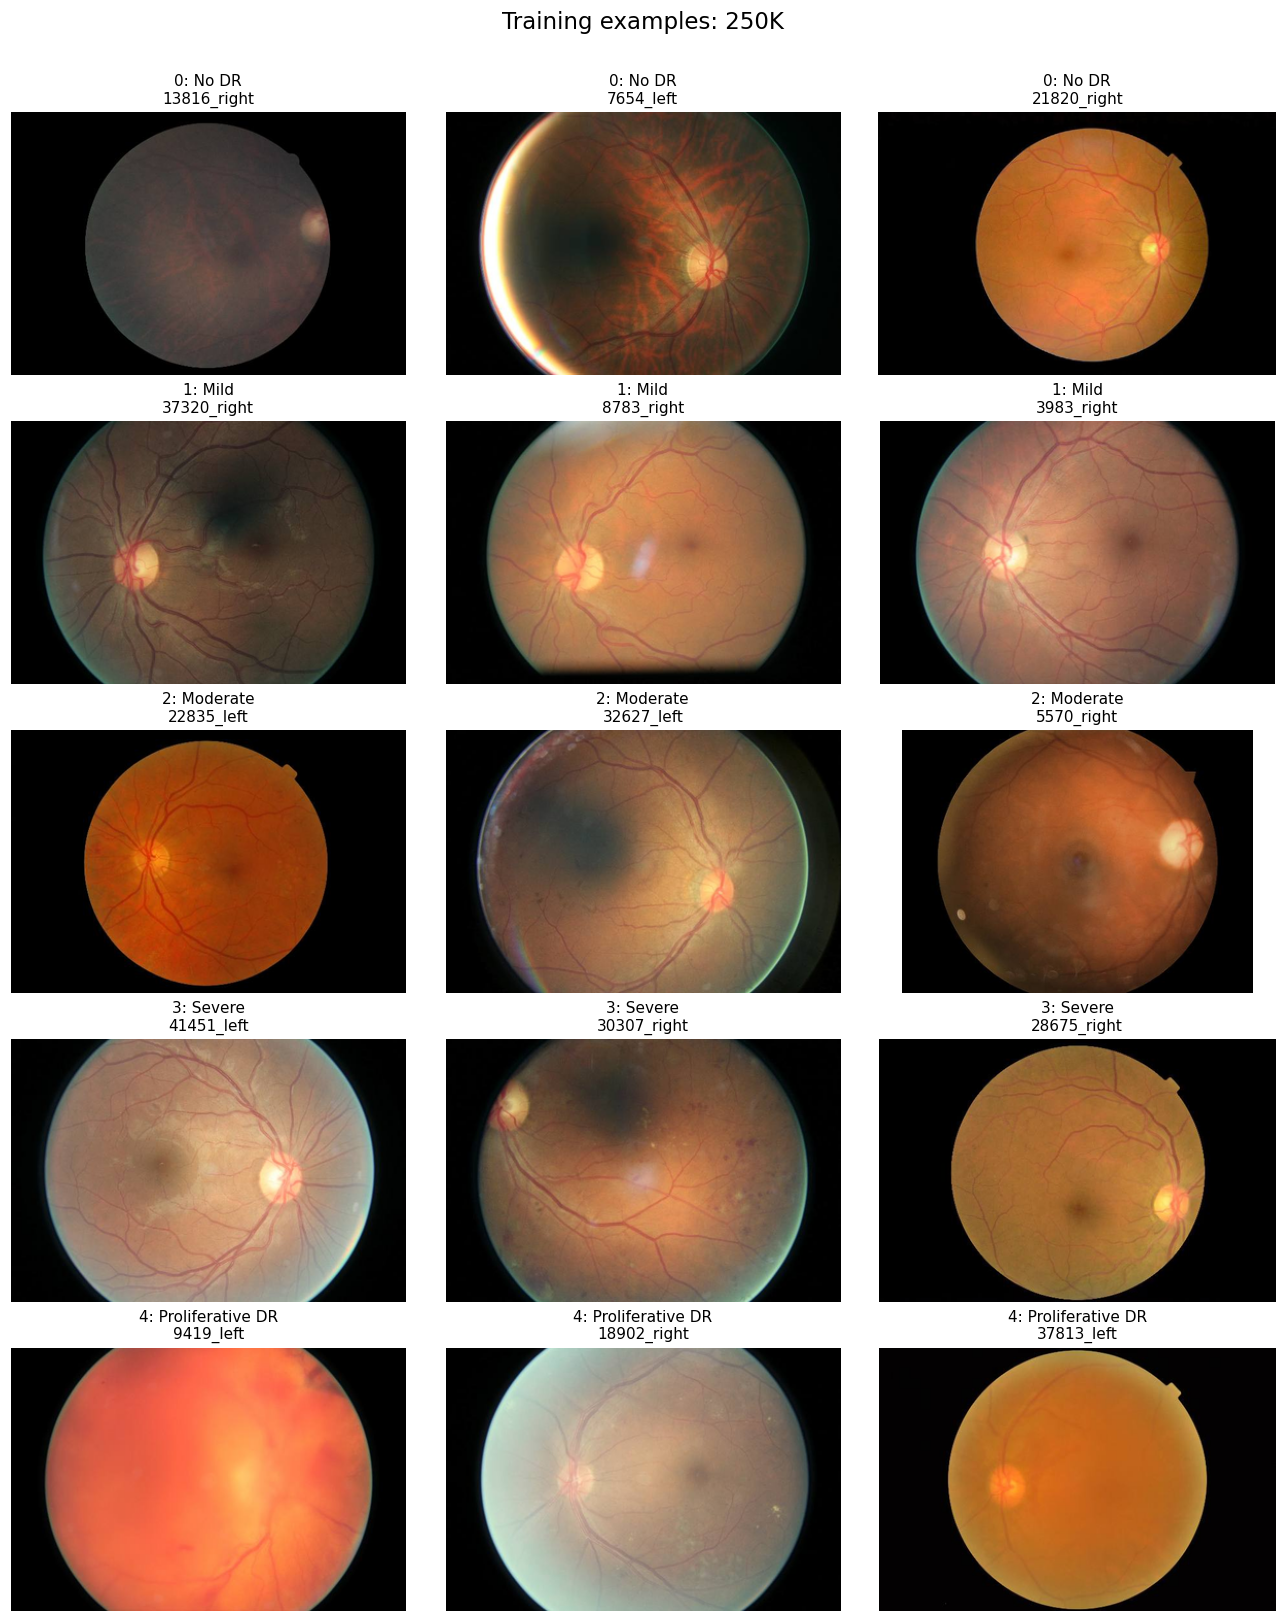

In [8]:
gallery, axes = plt.subplots(5, SAMPLES_PER_CLASS,
                            figsize=(4 * SAMPLES_PER_CLASS, 15), squeeze=False)
for grade in range(5):
    for col in range(SAMPLES_PER_CLASS):
        ax = axes[grade, col]
        ax.axis("off")
        if col < len(examples[grade]):
            name, image = examples[grade][col]
            ax.imshow(image)
            ax.set_title(f"{GRADE_NAMES[grade]}\n{name}", fontsize=10)
        else:
            ax.set_title(f"{GRADE_NAMES[grade]}\nNo example available", fontsize=10)
gallery.suptitle(f"Training examples: {CONFIG}", fontsize=15)
gallery.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [9]:
selected = {name: grade for grade, items in examples.items() for name, image in items}
samples = {
    CONFIG: {name: image for items in examples.values() for name, image in items}
}

for config in CONFIGS:
    if config != CONFIG:
        folder = PROJECT_ROOT / "data" / config
        assert (folder / "dataset_info.json").exists(), f"Missing processed dataset: {folder}"
        other = tfds.builder_from_directory(str(folder))
        ds = other.as_dataset(
            split="train", shuffle_files=False,
            decoders={"image": tfds.decode.SkipDecoding()},
            read_config=read_config,
        )
        samples[config] = {}
        for item in tqdm(tfds.as_numpy(ds), total=other.info.splits["train"].num_examples, desc=config):
            name = item["name"].decode("utf-8")
            if name in selected:
                assert int(item["label"]) == selected[name], f"Label differs: {config}, {name}"
                with Image.open(io.BytesIO(item["image"])) as source:
                    image = source.convert("RGB")
                image.thumbnail((PREVIEW_SIZE, PREVIEW_SIZE), Image.Resampling.LANCZOS)
                samples[config][name] = image
                if len(samples[config]) == len(selected):
                    break
        missing = set(selected) - set(samples[config])
        assert not missing, f"Samples missing from {config}: {sorted(missing)}"

    for name, image in samples[config].items():
        grade = selected[name]
        folder = SAMPLE_DIR / config / f"{grade}_{LABELS[grade].replace(' ', '_')}"
        folder.mkdir(parents=True, exist_ok=True)
        image.save(folder / f"{Path(name).stem}.jpg", quality=90)
    print(f"Saved {len(samples[config])} samples: {SAMPLE_DIR / config}")

gallery.savefig(SAMPLE_DIR / CONFIG / "contact_sheet.jpg", dpi=110, bbox_inches="tight")

1M:   0%|          | 0/35126 [00:00<?, ?it/s]

Saved 15 samples: D:\M L\Diabetic_Retinopathy_Detection_mini_project\data\demo_samples\1M
Saved 15 samples: D:\M L\Diabetic_Retinopathy_Detection_mini_project\data\demo_samples\250K


btgraham-300:   0%|          | 0/35126 [00:00<?, ?it/s]

Saved 15 samples: D:\M L\Diabetic_Retinopathy_Detection_mini_project\data\demo_samples\btgraham-300


## Compare the same image across formats



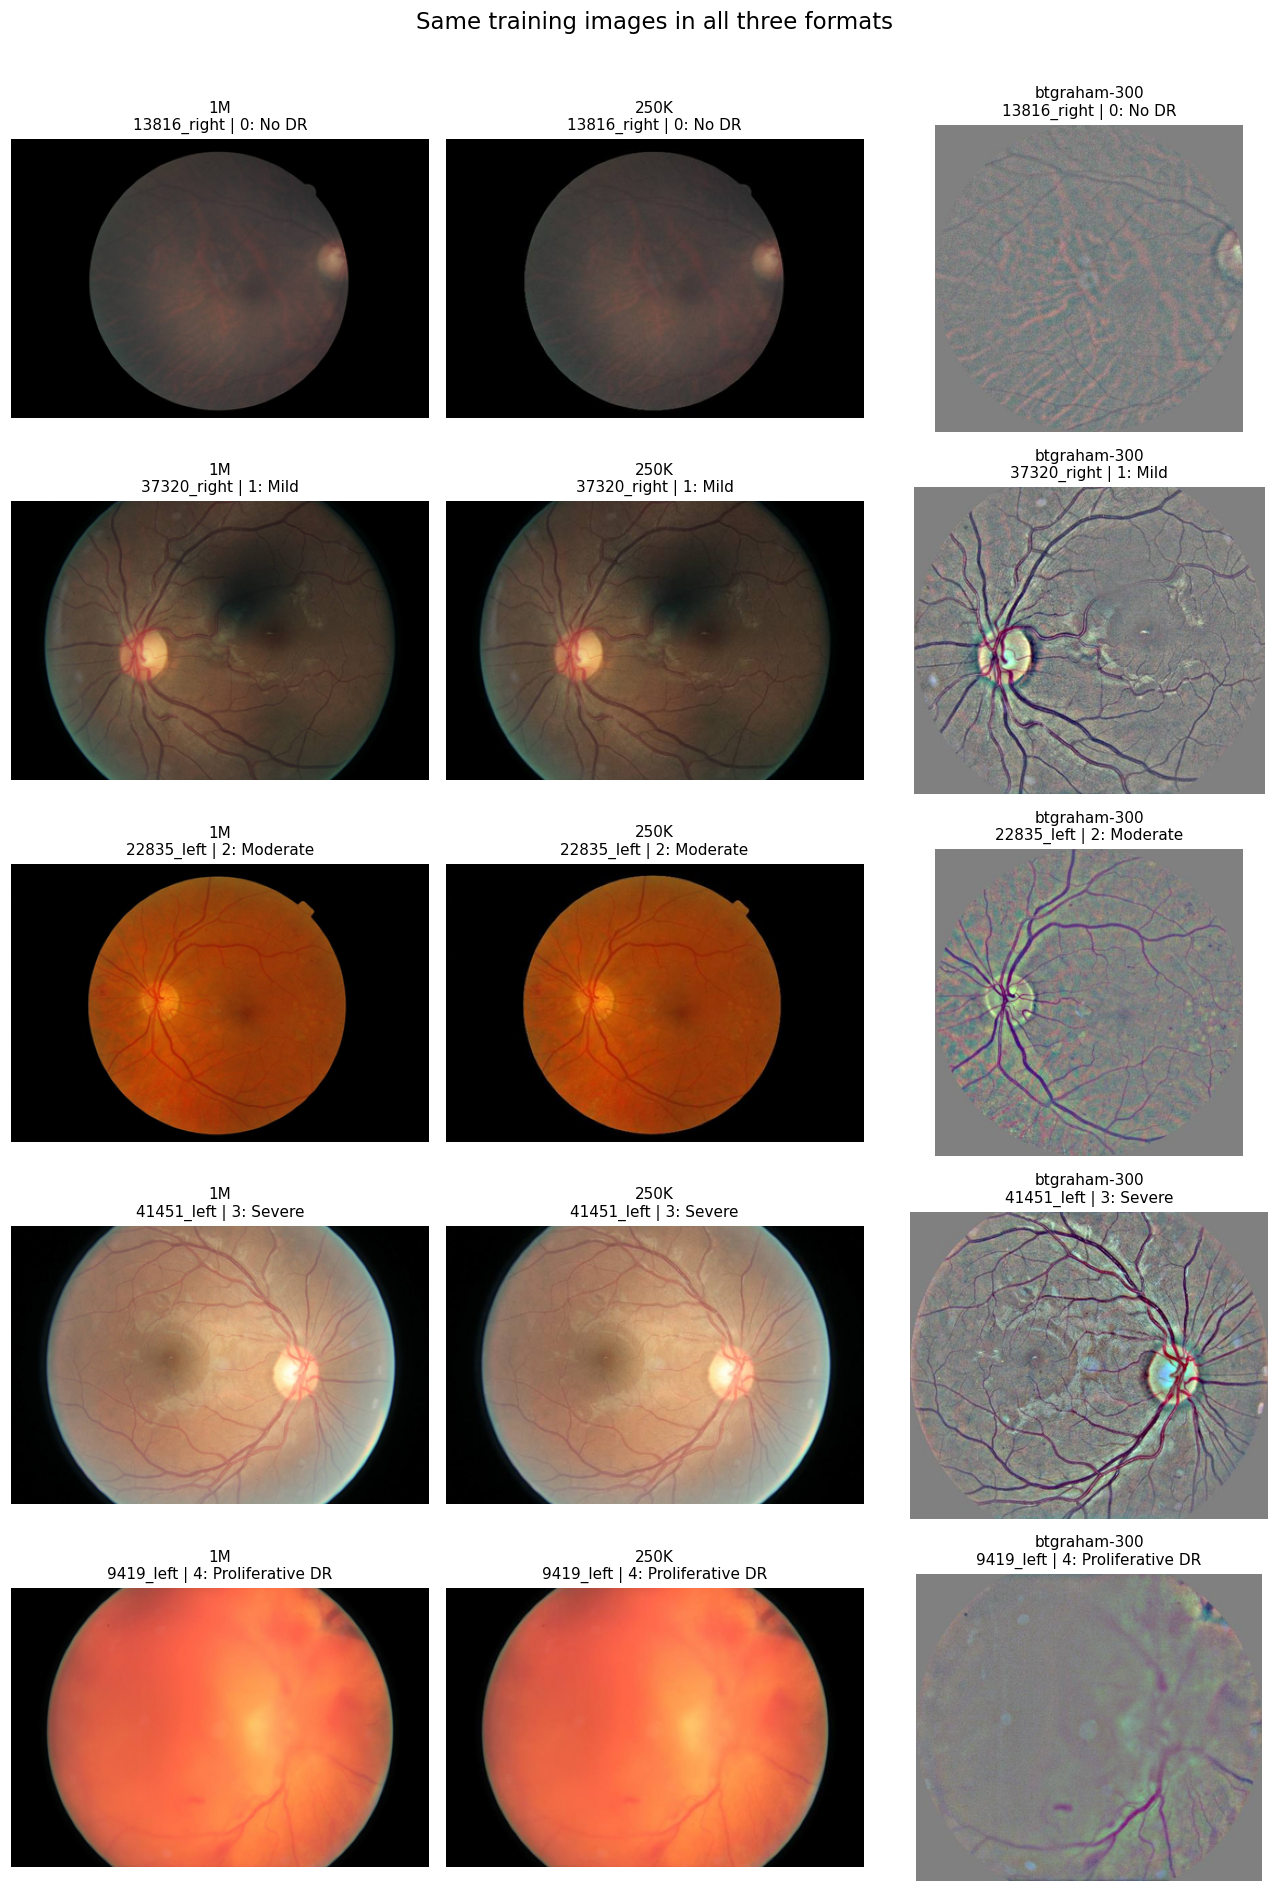

In [10]:
comparison_names = [items[0][0] for items in examples.values() if items]
comparison, axes = plt.subplots(
    len(comparison_names), 3, figsize=(12, 3.5 * len(comparison_names)), squeeze=False
)
for row, name in enumerate(comparison_names):
    for col, config in enumerate(CONFIGS):
        ax = axes[row, col]
        ax.imshow(samples[config][name])
        ax.set_title(f"{config}\n{name} | {GRADE_NAMES[selected[name]]}", fontsize=10)
        ax.axis("off")
comparison.suptitle("Same training images in all three formats", fontsize=15)
comparison.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()